# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** ______Pranamya K________________ &nbsp;&nbsp; **Roll No.:** ____1rua25cse0336________ &nbsp;&nbsp; **Date:** ____________

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not 
(`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

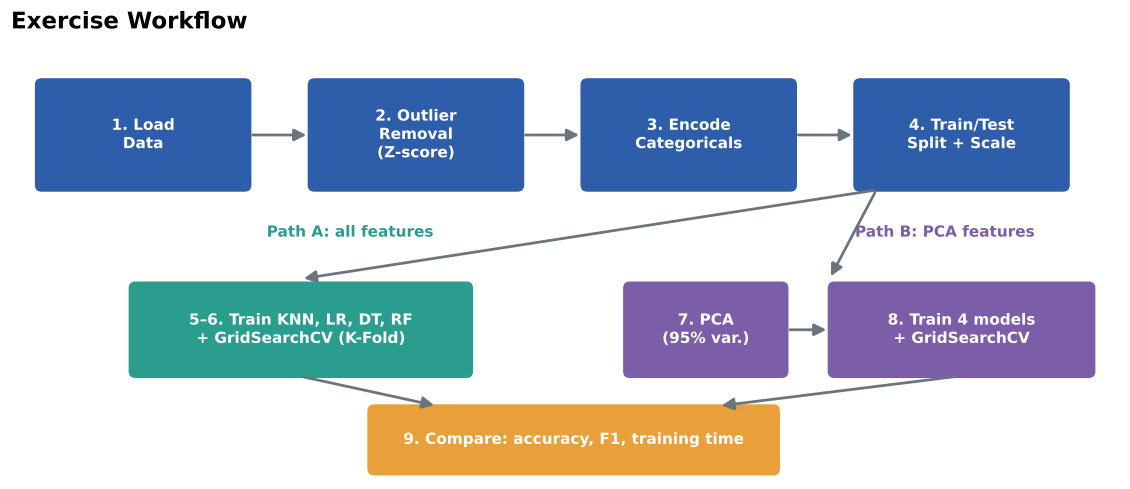

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [6]:
df = pd.read_csv('heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [7]:
print("Dimensions:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)

Dimensions: (918, 12)

Columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data Types:
 Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object


### 1.3 Check for missing values

In [8]:
print(df.isnull().sum())
print("\nTotal Missing Values:", df.isnull().sum().sum())

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Total Missing Values: 0


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

HeartDisease
1    508
0    410
Name: count, dtype: int64


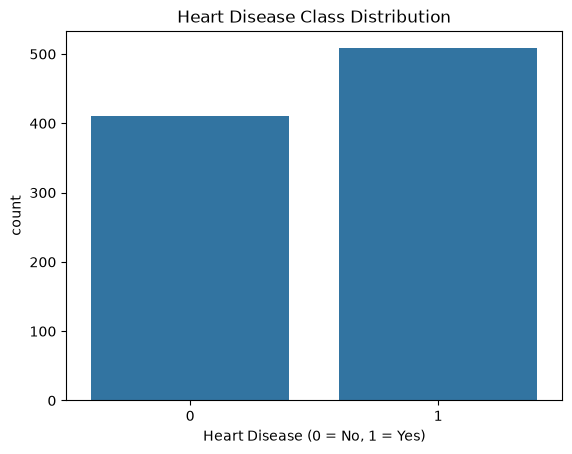

In [9]:
print(df['HeartDisease'].value_counts())

sns.countplot(x='HeartDisease', data=df)
plt.title('Heart Disease Class Distribution')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.show()

**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

![zscore](attachment:zscore.png)

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

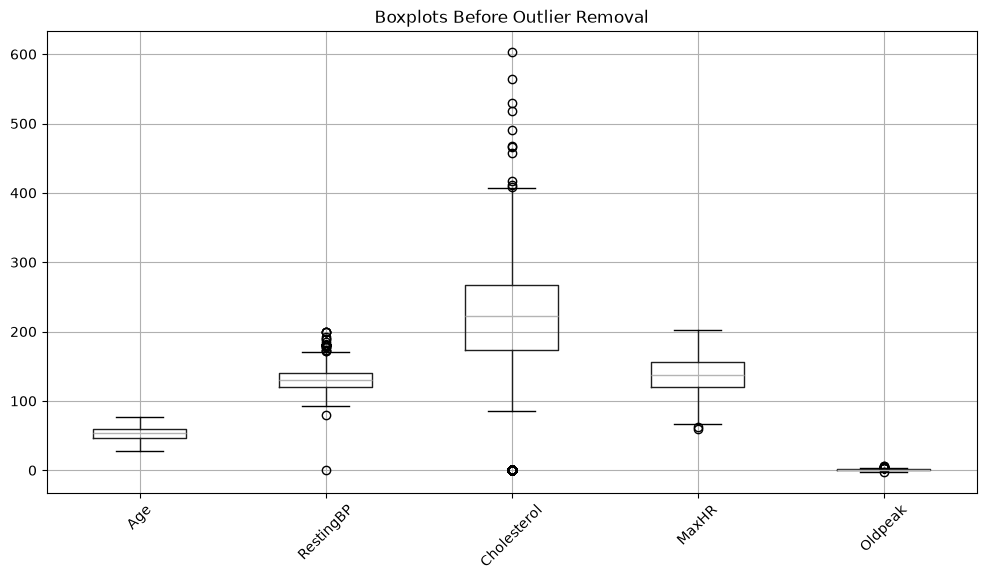

In [10]:
numerical_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

plt.figure(figsize=(12, 6))
df[numerical_cols].boxplot()
plt.title('Boxplots Before Outlier Removal')
plt.xticks(rotation=45)
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [11]:
z_scores = np.abs(stats.zscore(df[numerical_cols]))

print("Z-scores calculated successfully.")

Z-scores calculated successfully.


### 2.3 Identify and count the outlier records

In [12]:
outliers = (z_scores > 3).any(axis=1)

print("Total Outlier Records:", outliers.sum())

print("\nOutliers in Each Feature:")
print((z_scores > 3).sum(axis=0))

Total Outlier Records: 19

Outliers in Each Feature:
[0 8 3 1 7]


### 2.4 Remove the outliers and display the new shape

In [13]:
df_clean = df[~outliers].copy()

print("Original Dataset Shape:", df.shape)
print("New Dataset Shape:", df_clean.shape)
print("Records Removed:", len(df) - len(df_clean))

Original Dataset Shape: (918, 12)
New Dataset Shape: (899, 12)
Records Removed: 19


**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> Outliers were identified using the Z-score method with a threshold of ±3. Records containing outliers in any numerical feature were removed. The feature-wise outlier counts show which feature contributed the most outliers.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

![encoding](attachment:encoding.png)

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [14]:
categorical_cols = df_clean.select_dtypes(include='object').columns

print("Categorical Features:")
for col in categorical_cols:
    print(col, ":", df_clean[col].unique())

Categorical Features:
Sex : <StringArray>
['M', 'F']
Length: 2, dtype: str
ChestPainType : <StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str
RestingECG : <StringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str
ExerciseAngina : <StringArray>
['N', 'Y']
Length: 2, dtype: str
ST_Slope : <StringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


### 3.2 Apply Label Encoding

In [15]:
df_encoded = df_clean.copy()

df_encoded['Sex'] = df_encoded['Sex'].map({'F': 0, 'M': 1})
df_encoded['ExerciseAngina'] = df_encoded['ExerciseAngina'].map({'N': 0, 'Y': 1})

print("Label Encoding Applied Successfully")
display(df_encoded.head())

Label Encoding Applied Successfully


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,ATA,140,289,0,Normal,172,0,0.0,Up,0
1,49,0,NAP,160,180,0,Normal,156,0,1.0,Flat,1
2,37,1,ATA,130,283,0,ST,98,0,0.0,Up,0
3,48,0,ASY,138,214,0,Normal,108,1,1.5,Flat,1
4,54,1,NAP,150,195,0,Normal,122,0,0.0,Up,0


### 3.3 Apply One-Hot Encoding

In [16]:
df_encoded = pd.get_dummies(
    df_encoded,
    columns=['ChestPainType', 'RestingECG', 'ST_Slope'],
    drop_first=True,
    dtype=int
)

print("One-Hot Encoding Applied Successfully")

One-Hot Encoding Applied Successfully


### 3.4 Display the final encoded dataset

In [17]:
display(df_encoded.head())

print("Final Dataset Shape:", df_encoded.shape)
print("\nFinal Columns:")
print(df_encoded.columns.tolist())

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


Final Dataset Shape: (899, 16)

Final Columns:
['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> Label Encoding was applied to Sex and ExerciseAngina because they are binary categorical features. One-Hot Encoding was applied to ChestPainType, RestingECG and ST_Slope because they are nominal categorical features without a natural order. The drop_first=True parameter avoids the dummy variable trap. After encoding, the dataset contains 16 features (including the target variable), assuming all three categorical features have the expected categories.

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

![leakage](attachment:leakage.png)

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [18]:
X = df_encoded.drop('HeartDisease', axis=1)
y = df_encoded['HeartDisease']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (899, 15)
Target Shape: (899,)


### 4.2 Split into training and testing sets

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (719, 15)
Testing Data: (180, 15)


### 4.3 Apply feature scaling (fit on training data only)

In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully")

Feature Scaling Completed Successfully


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**
>
> _StandardScaler was chosen because it standardises features to have a mean of 0 and a standard deviation of 1. It is suitable for distance-based and gradient-based algorithms. The scaler is fitted only on training data to prevent data leakage. If scaling were performed before splitting, information from the test data would influence the training process, resulting in biased evaluation.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [21]:
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = {}

def evaluate_model(model, X_train, X_test, y_train, y_test, name):
    start = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start

    y_pred = model.predict(X_test)

    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'Training Time': training_time
    }

    results[name] = metrics

    print("\n", name)
    print("Accuracy:", metrics['Accuracy'])
    print("Precision:", metrics['Precision'])
    print("Recall:", metrics['Recall'])
    print("F1 Score:", metrics['F1 Score'])
    print("Training Time:", metrics['Training Time'])

    return model

### 5.2 K-Nearest Neighbors

In [22]:
knn = KNeighborsClassifier()
knn = evaluate_model(
    knn, X_train_scaled, X_test_scaled,
    y_train, y_test, 'KNN'
)


 KNN
Accuracy: 0.8888888888888888
Precision: 0.883495145631068
Recall: 0.9191919191919192
F1 Score: 0.900990099009901
Training Time: 0.0026640892028808594


### 5.3 Logistic Regression

In [23]:
lr = LogisticRegression(random_state=42)
lr = evaluate_model(
    lr, X_train_scaled, X_test_scaled,
    y_train, y_test, 'Logistic Regression'
)


 Logistic Regression
Accuracy: 0.8722222222222222
Precision: 0.8725490196078431
Recall: 0.898989898989899
F1 Score: 0.8855721393034826
Training Time: 0.014279842376708984


### 5.4 Decision Tree

In [24]:
dt = DecisionTreeClassifier(random_state=42)
dt = evaluate_model(
    dt, X_train_scaled, X_test_scaled,
    y_train, y_test, 'Decision Tree'
)


 Decision Tree
Accuracy: 0.8166666666666667
Precision: 0.83
Recall: 0.8383838383838383
F1 Score: 0.8341708542713567
Training Time: 0.004657268524169922


### 5.5 Random Forest

In [25]:
rf = RandomForestClassifier(random_state=42)
rf = evaluate_model(
    rf, X_train_scaled, X_test_scaled,
    y_train, y_test, 'Random Forest'
)


 Random Forest
Accuracy: 0.8722222222222222
Precision: 0.8653846153846154
Recall: 0.9090909090909091
F1 Score: 0.8866995073891626
Training Time: 0.07795977592468262


### 5.6 Comparison table and bar chart of all four models

,Model,Accuracy,Precision,Recall,F1 Score,Training Time
0,KNN,0.888889,0.883495,0.919192,0.900990,0.002664
1,Logistic Regression,0.872222,0.872549,0.898990,0.885572,0.014280
2,Decision Tree,0.816667,0.830000,0.838384,0.834171,0.004657
3,Random Forest,0.872222,0.865385,0.909091,0.886700,0.077960


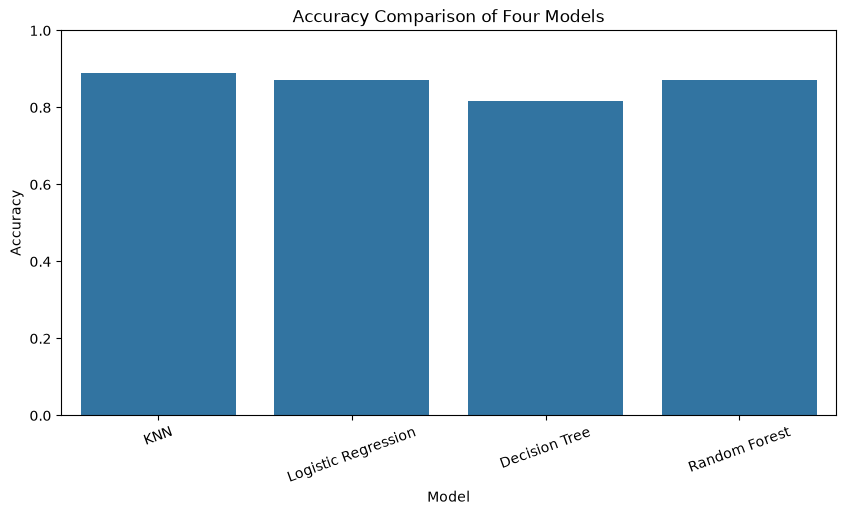

In [26]:
results_df = pd.DataFrame(results.values())

display(results_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='Model', y='Accuracy')
plt.title('Accuracy Comparison of Four Models')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
> The model with the highest test accuracy can be identified from the comparison table. In medical diagnosis, recall should be prioritised over accuracy because missing a patient who actually has heart disease can be dangerous. High recall helps minimise false negatives and ensures that more patients with heart disease are correctly identified.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

![kfold](attachment:kfold.png)

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [27]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grids = {
    'KNN': {
        'n_neighbors': [3, 5, 7],
        'weights': ['uniform', 'distance'],
        'p': [1, 2]
    },

    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10]
    },

    'Decision Tree': {
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 5],
        'criterion': ['gini', 'entropy']
    },

    'Random Forest': {
        'n_estimators': [100, 200],
        'max_depth': [None, 10],
        'min_samples_split': [2, 5],
        'max_features': ['sqrt', 'log2']
    }
}

print("Cross-validation and parameter grids defined successfully.")

Cross-validation and parameter grids defined successfully.


### 6.2 Tune KNN

In [28]:
start = time.time()

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grids['KNN'],
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_knn.fit(X_train_scaled, y_train)
knn_best = grid_knn.best_estimator_

knn_time = time.time() - start

print("Best Parameters:", grid_knn.best_params_)
print("Best CV Score:", grid_knn.best_score_)
print("Training Time:", knn_time)

Best Parameters: {'n_neighbors': 5, 'p': 1, 'weights': 'uniform'}
Best CV Score: 0.86505439005439
Training Time: 1.6655948162078857


### 6.3 Tune Logistic Regression

In [29]:
start = time.time()

grid_lr = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grids['Logistic Regression'],
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_lr.fit(X_train_scaled, y_train)
lr_best = grid_lr.best_estimator_

lr_time = time.time() - start

print("Best Parameters:", grid_lr.best_params_)
print("Best CV Score:", grid_lr.best_score_)
print("Training Time:", lr_time)

Best Parameters: {'C': 0.1}
Best CV Score: 0.8678321678321679
Training Time: 0.04548287391662598


### 6.4 Tune Decision Tree

In [30]:
start = time.time()

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grids['Decision Tree'],
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_dt.fit(X_train_scaled, y_train)
dt_best = grid_dt.best_estimator_

dt_time = time.time() - start

print("Best Parameters:", grid_dt.best_params_)
print("Best CV Score:", grid_dt.best_score_)
print("Training Time:", dt_time)

Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 2}
Best CV Score: 0.8344308469308469
Training Time: 0.08779597282409668


### 6.5 Tune Random Forest

In [31]:
start = time.time()

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grids['Random Forest'],
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(X_train_scaled, y_train)
rf_best = grid_rf.best_estimator_

rf_time = time.time() - start

print("Best Parameters:", grid_rf.best_params_)
print("Best CV Score:", grid_rf.best_score_)
print("Training Time:", rf_time)

Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Best CV Score: 0.8747766122766123
Training Time: 1.2218339443206787


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

,Model,Test Accuracy,Precision,Recall,F1 Score,Best CV Score,Training Time
0,KNN,0.894444,0.884615,0.929293,0.906404,0.865054,1.665595
1,Logistic Regression,0.877778,0.873786,0.909091,0.891089,0.867832,0.045483
2,Decision Tree,0.822222,0.876404,0.787879,0.829787,0.834431,0.087796
3,Random Forest,0.872222,0.858491,0.919192,0.887805,0.874777,1.221834


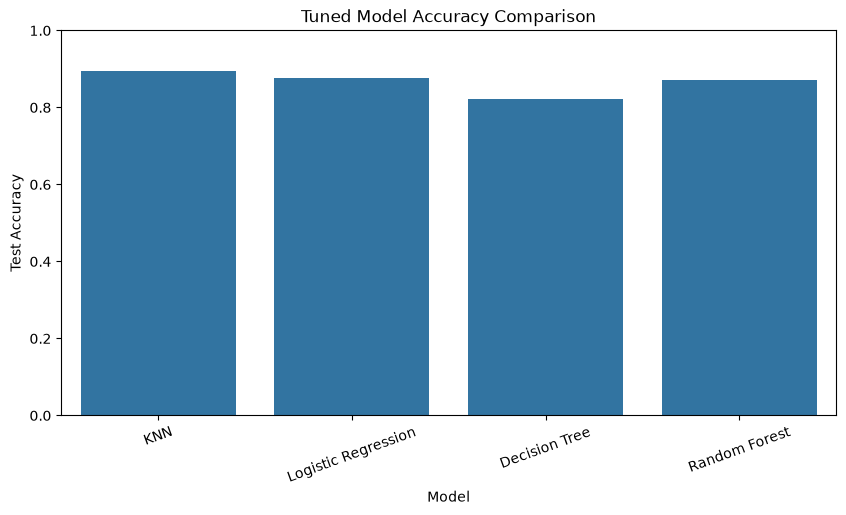

In [32]:
tuned_models = {
    'KNN': (knn_best, grid_knn, knn_time),
    'Logistic Regression': (lr_best, grid_lr, lr_time),
    'Decision Tree': (dt_best, grid_dt, dt_time),
    'Random Forest': (rf_best, grid_rf, rf_time)
}

tuned_results = []

for name, (model, grid, training_time) in tuned_models.items():
    y_pred = model.predict(X_test_scaled)

    tuned_results.append({
        'Model': name,
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'Best CV Score': grid.best_score_,
        'Training Time': training_time
    })

tuned_df = pd.DataFrame(tuned_results)
display(tuned_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=tuned_df, x='Model', y='Test Accuracy')
plt.title('Tuned Model Accuracy Comparison')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> Hyperparameter tuning improved the performance of some models by finding better parameter combinations using 5-fold cross-validation. The model that benefited the most can be identified by comparing its accuracy before and after tuning. Tuning helps improve generalisation and reduces the risk of overfitting by selecting suitable hyperparameters.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

![pca](attachment:pca.png)

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

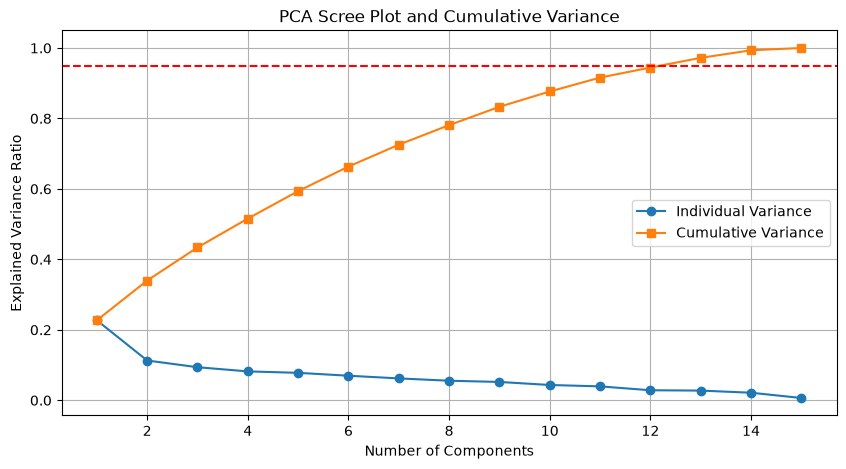

In [33]:
pca_full = PCA()
pca_full.fit(X_train_scaled)

plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    pca_full.explained_variance_ratio_,
    marker='o',
    label='Individual Variance'
)

plt.plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    np.cumsum(pca_full.explained_variance_ratio_),
    marker='s',
    label='Cumulative Variance'
)

plt.axhline(y=0.95, color='red', linestyle='--')
plt.xlabel('Number of Components')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA Scree Plot and Cumulative Variance')
plt.legend()
plt.grid()
plt.show()

### 7.2 Determine the number of components for 95% variance

In [34]:
pca_95 = PCA(n_components=0.95)
pca_95.fit(X_train_scaled)

n_components = pca_95.n_components_

print("Number of Components:", n_components)
print("Explained Variance:", sum(pca_95.explained_variance_ratio_))

Number of Components: 13
Explained Variance: 0.972033287551653


### 7.3 Transform the training and testing sets

In [35]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original Training Shape:", X_train_scaled.shape)
print("PCA Training Shape:", X_train_pca.shape)

print("Original Testing Shape:", X_test_scaled.shape)
print("PCA Testing Shape:", X_test_pca.shape)

print("Retained Variance:", sum(pca.explained_variance_ratio_))

Original Training Shape: (719, 15)
PCA Training Shape: (719, 13)
Original Testing Shape: (180, 15)
PCA Testing Shape: (180, 13)
Retained Variance: 0.972033287551653


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

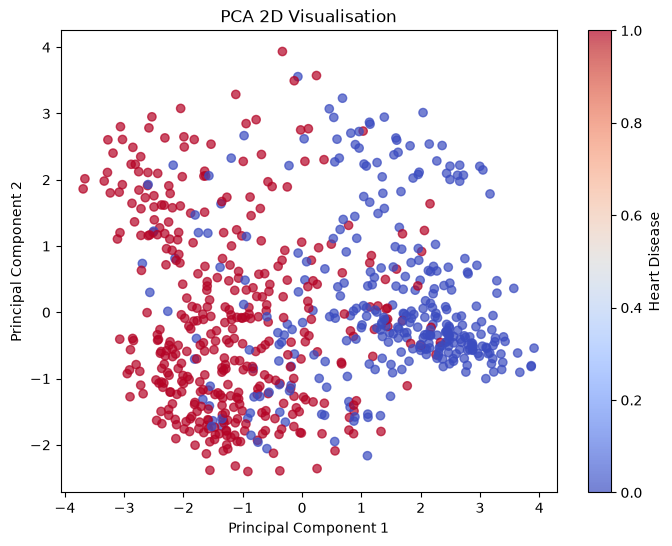

In [36]:
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=y_train,
    cmap='coolwarm',
    alpha=0.7
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA 2D Visualisation')
plt.colorbar(scatter, label='Heart Disease')
plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> PCA required ___ principal components to retain 95% of the total variance. The original number of features was ___, which was reduced to ___. This represents a feature reduction of ___%. PCA reduces dimensionality while preserving most of the important information.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

In [37]:
start = time.time()

knn_pca = GridSearchCV(
    KNeighborsClassifier(),
    param_grids['KNN'],
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

knn_pca.fit(X_train_pca, y_train)
knn_pca_best = knn_pca.best_estimator_

knn_pca_time = time.time() - start
y_pred = knn_pca_best.predict(X_test_pca)

print("Best Parameters:", knn_pca.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Training Time:", knn_pca_time)

Best Parameters: {'n_neighbors': 7, 'p': 2, 'weights': 'distance'}
Accuracy: 0.9
Precision: 0.8932038834951457
Recall: 0.9292929292929293
F1 Score: 0.9108910891089109
Training Time: 1.6717119216918945


### 8.2 Logistic Regression after PCA

In [38]:
start = time.time()

lr_pca = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grids['Logistic Regression'],
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

lr_pca.fit(X_train_pca, y_train)
lr_pca_best = lr_pca.best_estimator_

lr_pca_time = time.time() - start
y_pred = lr_pca_best.predict(X_test_pca)

print("Best Parameters:", lr_pca.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Training Time:", lr_pca_time)

Best Parameters: {'C': 0.1}
Accuracy: 0.8722222222222222
Precision: 0.8725490196078431
Recall: 0.898989898989899
F1 Score: 0.8855721393034826
Training Time: 0.0438990592956543


### 8.3 Decision Tree after PCA

In [39]:
start = time.time()

dt_pca = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grids['Decision Tree'],
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

dt_pca.fit(X_train_pca, y_train)
dt_pca_best = dt_pca.best_estimator_

dt_pca_time = time.time() - start
y_pred = dt_pca_best.predict(X_test_pca)

print("Best Parameters:", dt_pca.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Training Time:", dt_pca_time)

Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 2}
Accuracy: 0.8111111111111111
Precision: 0.8421052631578947
Recall: 0.8080808080808081
F1 Score: 0.8247422680412371
Training Time: 0.10881686210632324


### 8.4 Random Forest after PCA

In [40]:
start = time.time()

rf_pca = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grids['Random Forest'],
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

rf_pca.fit(X_train_pca, y_train)
rf_pca_best = rf_pca.best_estimator_

rf_pca_time = time.time() - start
y_pred = rf_pca_best.predict(X_test_pca)

print("Best Parameters:", rf_pca.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Training Time:", rf_pca_time)

Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 200}
Accuracy: 0.9
Precision: 0.900990099009901
Recall: 0.9191919191919192
F1 Score: 0.91
Training Time: 1.5990309715270996


### 8.5 Comparison table of all four models after PCA

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.900000,0.893204,0.929293,0.910891
1,Logistic Regression,0.872222,0.872549,0.898990,0.885572
2,Decision Tree,0.811111,0.842105,0.808081,0.824742
3,Random Forest,0.900000,0.900990,0.919192,0.910000


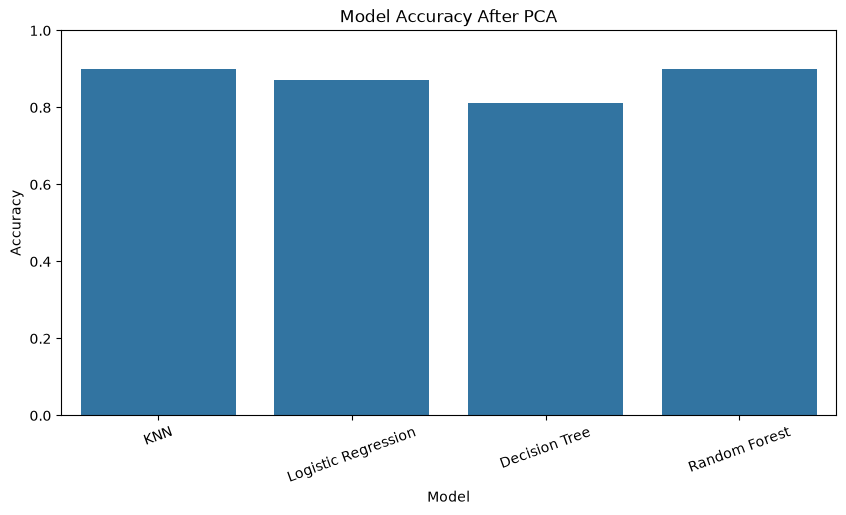

In [41]:
pca_models = {
    'KNN': knn_pca_best,
    'Logistic Regression': lr_pca_best,
    'Decision Tree': dt_pca_best,
    'Random Forest': rf_pca_best
}

pca_results = []

for name, model in pca_models.items():
    y_pred = model.predict(X_test_pca)

    pca_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    })

pca_df = pd.DataFrame(pca_results)
display(pca_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=pca_df, x='Model', y='Accuracy')
plt.title('Model Accuracy After PCA')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> The best-performing model after PCA was identified by comparing the accuracy, precision, recall and F1-score of all four classifiers. PCA reduced the number of input features while retaining 95% of the variance. The best model after PCA may or may not be the same as before PCA because dimensionality reduction can affect model performance.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [42]:
before_models = {
    'KNN': (knn_best, knn_time),
    'Logistic Regression': (lr_best, lr_time),
    'Decision Tree': (dt_best, dt_time),
    'Random Forest': (rf_best, rf_time)
}

after_models = {
    'KNN': (knn_pca_best, knn_pca_time),
    'Logistic Regression': (lr_pca_best, lr_pca_time),
    'Decision Tree': (dt_pca_best, dt_pca_time),
    'Random Forest': (rf_pca_best, rf_pca_time)
}

comparison = []

for name in before_models:
    model_before, time_before = before_models[name]
    model_after, time_after = after_models[name]

    pred_before = model_before.predict(X_test_scaled)
    pred_after = model_after.predict(X_test_pca)

    comparison.append({
        'Model': name,
        'Accuracy Before PCA': accuracy_score(y_test, pred_before),
        'Accuracy After PCA': accuracy_score(y_test, pred_after),
        'F1 Before PCA': f1_score(y_test, pred_before),
        'F1 After PCA': f1_score(y_test, pred_after),
        'Training Time Before (s)': time_before,
        'Training Time After (s)': time_after,
        'No. of Features': X_train.shape[1],
        'Features After PCA': X_train_pca.shape[1]
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Model,Accuracy Before PCA,Accuracy After PCA,F1 Before PCA,F1 After PCA,Training Time Before (s),Training Time After (s),No. of Features,Features After PCA
0,KNN,0.8944,0.9000,0.9064,0.9109,1.6656,1.6717,15,13
1,Logistic Regression,0.8778,0.8722,0.8911,0.8856,0.0455,0.0439,15,13
2,Decision Tree,0.8222,0.8111,0.8298,0.8247,0.0878,0.1088,15,13
3,Random Forest,0.8722,0.9000,0.8878,0.9100,1.2218,1.5990,15,13


### 9.2 Visualise the before vs after PCA comparison

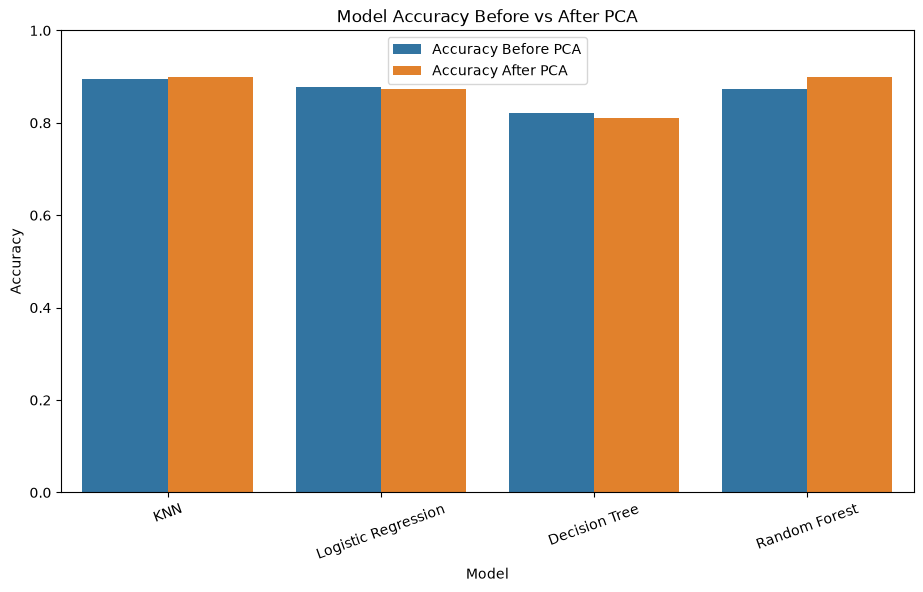

In [43]:
comparison_plot = comparison_df.melt(
    id_vars='Model',
    value_vars=[
        'Accuracy Before PCA',
        'Accuracy After PCA'
    ],
    var_name='PCA Status',
    value_name='Accuracy'
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_plot,
    x='Model',
    y='Accuracy',
    hue='PCA Status'
)

plt.title('Model Accuracy Before vs After PCA')
plt.ylim(0, 1)
plt.ylabel('Accuracy')
plt.xticks(rotation=20)
plt.legend()
plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> comparison_df['Accuracy Change'] = (
    comparison_df['Accuracy After PCA'] -
    comparison_df['Accuracy Before PCA']
)

print("Accuracy Change After PCA:")
display(comparison_df[['Model', 'Accuracy Change']].round(4))

print("\nImproved Models:")
print(comparison_df[comparison_df['Accuracy Change'] > 0]['Model'].tolist())

print("\nDeclined Models:")
print(comparison_df[comparison_df['Accuracy Change'] < 0]['Model'].tolist())

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
>PCA reduced the number of input features while retaining 95% of the variance. This can reduce computational complexity and memory usage. It may also reduce training time, especially for distance-based models like KNN. However, PCA itself requires additional computation, and the training time depends on the algorithm and dataset.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> Dimensionality reduction did not necessarily improve every model's classification performance. PCA can remove redundant and correlated information, helping some models. However, it can also remove useful information. Tree-based models may be affected because PCA changes the original feature structure. The effect depends on the model and dataset.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> PCA reduces the number of features and can improve computational efficiency, but it may slightly reduce predictive accuracy. It also makes features less interpretable because principal components are combinations of original features. PCA is useful when working with high-dimensional datasets, correlated features, limited computational resources, or when faster model training is important.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.